# Estrés macro y apetito de riesgo en la cartera de consumo colombiana

**Pregunta de negocio.** Un comité de riesgo de un banco o una fintech de consumo necesita responder cuatro cosas:
qué explicó el deterioro de 2023–2024, qué señal lo habría anticipado, cuánto podría costar un nuevo ciclo adverso
y qué límites de apetito deberían regir hoy por producto.

**Datos.** Todo sale de fuentes públicas oficiales, normalizadas en `../datos`:
- SFC: cartera por altura de mora y calificación, por entidad y producto, mensual de 2015-01 a 2026-08 (datos.gov.co `rvii-eis8`).
- BanRep: tasa de política monetaria (serie 59).
- DANE: desocupación (GEIH), IPC e ISE.

**Lo que no es.** La SFC publica saldos agregados por entidad, no créditos individuales. El ICV90 de aquí es saldo vencido a más de
90 días sobre saldo bruto: se mueve con los castigos y con el crecimiento del denominador, y no es una PD. Las LGD son supuestos
de trabajo explícitos. El resultado sirve para dimensionar y priorizar, no para provisionar.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd())); sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import estres as E
from comun import cartera, cop_billones
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
c = cartera(); s = E.series_consumo(c); p = E.por_producto(c); d = E.base_modelo(s)
co = c[c.familia == "Consumo"]
print(f"Filas entidad-producto-mes: {len(c):,} | consumo: {len(co):,} | entidades con consumo: {co.codigo_entidad.nunique()}")
print(f"Periodo: {s.index.min()} a {s.index.max()} | saldo de consumo último mes: {cop_billones(s.saldo.iloc[-1])}")
print(f"Filas que reconcilian vigente + vencida = saldo: {c.reconcilia.mean():.2%}")
assert c.reconcilia.mean() > 0.99

Filas entidad-producto-mes: 86,661 | consumo: 26,700 | entidades con consumo: 62
Periodo: 2015-01 a 2026-08 | saldo de consumo último mes: 228,80 billones
Filas que reconcilian vigente + vencida = saldo: 99.96%


## 1. El ciclo observado

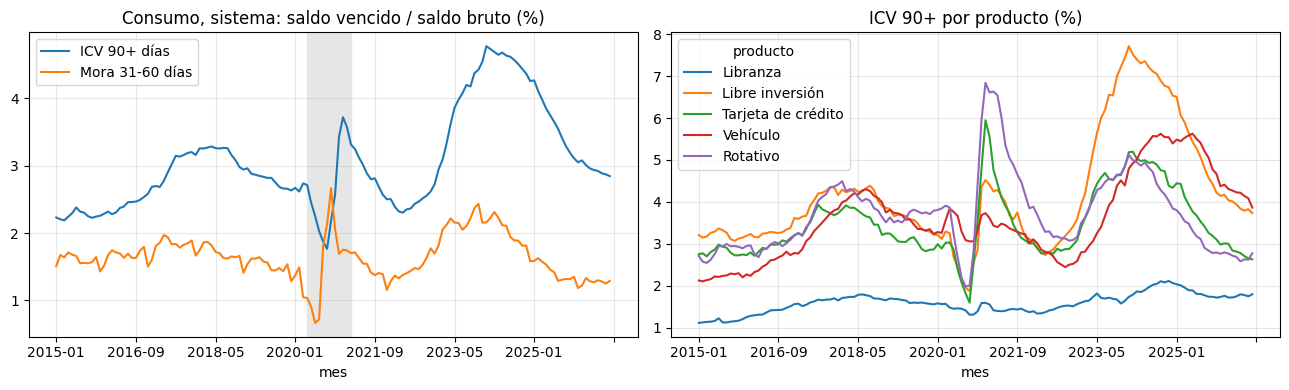

Valle 2022-04: 2.30% -> pico 2024-01: 4.77% -> último 2026-08: 2.84%


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(100 * s[["icv90", "temprana"]]).rename(columns={"icv90": "ICV 90+ días", "temprana": "Mora 31-60 días"}).plot(ax=ax[0])
ax[0].set_title("Consumo, sistema: saldo vencido / saldo bruto (%)"); ax[0].axvspan(s.index.get_loc("2020-04"), s.index.get_loc("2021-03"), color="0.9")
(100 * p["icv90"].unstack()[E.PRODUCTOS]).plot(ax=ax[1]); ax[1].set_title("ICV 90+ por producto (%)")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "ciclo_consumo.png", dpi=130); plt.show()
pico = s.icv90.idxmax(); valle = s.loc["2022-01":pico].icv90.idxmin()
print(f"Valle {valle}: {s.icv90[valle]:.2%} -> pico {pico}: {s.icv90[pico]:.2%} -> último {s.index[-1]}: {s.icv90.iloc[-1]:.2%}")

**Lectura.** La franja gris son los alivios de la SFC de 2020 (Circulares 007 y 014): la mora reportada *cae* en plena
recesión porque los periodos de gracia congelan la altura de mora. Por eso ningún modelo estimado sobre esta muestra puede leer
2020 como un episodio normal, y el modelo satélite lleva una variable indicadora para ese periodo.

## 2. ¿Qué explicó el deterioro de 2023–2024? Descomposición tasa / mezcla

In [3]:
ss = E.shift_share(p, valle, pico)
tot = s.icv90[pico] - s.icv90[valle]
print(f"Cambio total del ICV90: {tot*1e4:,.0f} pb; suma de la descomposición: {ss.total.sum()*1e4:,.0f} pb")
assert abs(ss.total.sum() - tot) < 1e-3, "la descomposición debe cuadrar con el agregado (salvo productos que entran/salen)"
print(f"Efecto tasa (deterioro dentro de cada producto): {ss.efecto_tasa.sum()*1e4:,.0f} pb")
print(f"Efecto mezcla (cambio de composición): {ss.efecto_mezcla.sum()*1e4:,.0f} pb")
(1e4 * ss[["efecto_tasa", "efecto_mezcla", "interaccion"]]).round(0)

Cambio total del ICV90: 247 pb; suma de la descomposición: 247 pb
Efecto tasa (deterioro dentro de cada producto): 252 pb
Efecto mezcla (cambio de composición): 2 pb


,efecto_tasa,efecto_mezcla,interaccion
producto,,,
Libre inversión,174.0000,-9.0000,-16.0000
Tarjeta de crédito,40.0000,6.0000,5.0000
Vehículo,18.0000,3.0000,2.0000
Libranza,13.0000,-1.0000,-0.0000
Rotativo,5.0000,1.0000,0.0000
Otros consumo,2.0000,3.0000,1.0000
Consumo empleados,0.0000,0.0000,0.0000
Consumo bajo monto,0.0000,-0.0000,-0.0000


In [4]:
lider = ss.index[0]
print(f"{lider} aporta {ss.total.iloc[0]/tot:.0%} del deterioro con {ss.peso_inicial.iloc[0]:.0%} del saldo inicial.")
print(f"Libre inversión + tarjeta: {(ss.loc[['Libre inversión','Tarjeta de crédito'],'total'].sum()/tot):.0%} del cambio.")

Libre inversión aporta 61% del deterioro con 35% del saldo inicial.
Libre inversión + tarjeta: 81% del cambio.


**Lectura.** El deterioro fue un fenómeno de *tasa*, no de mezcla: los mismos productos se dañaron por dentro. La concentración
en libre inversión y tarjeta, que son los productos sin garantía ni descuento de nómina, apunta a la originación de 2021–2022
como origen. Libranza casi no se movió.

## 3. Primera hipótesis: el desempleo como motor. Resultado: falsa en esta muestra

La intuición de manual es que la mora de consumo sigue al desempleo. Se mide la correlación del ICV90 con cada variable rezagada.

In [5]:
corr = E.correlaciones_adelanto(d)
corr.round(2)

,temprana,desempleo_12m,tpm,inflacion,crec
rezago_meses,,,,,
0,0.4900,-0.1200,0.6000,0.1800,-0.8000
3,0.7500,-0.1000,0.7000,0.3400,-0.7100
6,0.6600,-0.0900,0.7800,0.5100,-0.5200
9,0.5400,-0.1300,0.8200,0.6800,-0.2400
12,0.4300,-0.1500,0.8000,0.8200,0.0500
18,0.1200,-0.0200,0.5700,0.8700,0.3900
24,-0.0900,0.2900,0.1800,0.6000,0.3700


In [6]:
print(f"Correlación máxima con desempleo (12m): {corr.desempleo_12m.max():.2f} | con inflación: {corr.inflacion.max():.2f} "
      f"(rezago {corr.inflacion.idxmax()}m) | con TPM: {corr.tpm.max():.2f} (rezago {corr.tpm.idxmax()}m)")
print(f"Crecimiento del crédito: contemporáneo {corr.crec.loc[0]:.2f}, a 18 meses {corr.crec.loc[18]:.2f}")

Correlación máxima con desempleo (12m): 0.29 | con inflación: 0.87 (rezago 18m) | con TPM: 0.82 (rezago 9m)
Crecimiento del crédito: contemporáneo -0.80, a 18 meses 0.39


**Lectura.** El desempleo no anticipa la mora en 2015–2026: los alivios de 2020 rompieron la relación justo en el mayor
choque de empleo de la muestra. Lo que sí anticipa es la combinación de inflación (que erosiona el ingreso disponible) y de tasas
(que encarecen el servicio de la deuda variable y la tarjeta), con 9 a 18 meses de rezago. El signo del crecimiento del crédito
cambia con el rezago: contemporáneamente el crédito que crece diluye la mora (más denominador sano); 18 meses después, esas
cosechas maduran y la mora sube. Ese es el mecanismo de cosecha que un comité debe vigilar.

## 4. Alerta temprana a nivel entidad

Si la mora temprana (31–60 días) sirve como alerta, un aumento en una entidad debe anticipar su mora 90+ *más allá* del ciclo
común. Panel entidad-mes con efectos fijos de mes (que absorben el ciclo) y errores agrupados por entidad.

In [7]:
pa = E.panel_alerta_temprana(c)
print(f"Observaciones: {pa['n']:,} de {pa['entidades']} entidades con más de 100.000 millones en consumo")
print(f"Beta: {pa['beta']:.2f} (t = {pa['t']:.1f}). Por cada 10 pb de aumento de mora temprana en 3 meses, "
      f"el ICV90 de la entidad sube {10*pa['beta']:.1f} pb en los 3 meses siguientes, descontado el ciclo.")
assert pa["t"] > 2.6

Observaciones: 4,092 de 42 entidades con más de 100.000 millones en consumo
Beta: 0.34 (t = 6.9). Por cada 10 pb de aumento de mora temprana en 3 meses, el ICV90 de la entidad sube 3.4 pb en los 3 meses siguientes, descontado el ciclo.


**Lectura.** La mora temprana es una alerta útil y barata: está en el reporte mensual y anticipa la mora dura de la misma
entidad con un trimestre de ventaja. Se usa como segundo eje del semáforo de entidades (sección 8).

## 5. Modelo satélite: selección de rezagos

Especificación: $\text{logit}(ICV90_t) = c + \rho\,\text{logit}(ICV90_{t-1}) + \beta_1 TPM_{t-a} + \beta_2 \pi_{t-b} + \beta_3 g_{t-k} + \delta\,\text{alivios}_t$,
donde $g$ es el crecimiento anual del saldo de consumo. Los rezagos se eligen por AIC en una rejilla de 100 combinaciones,
todas estimadas **sobre la misma muestra** (si no, el AIC compara modelos con distinta cantidad de datos).

In [8]:
tabla = E.seleccionar_rezagos(d)
print("Mejor especificación por AIC sin restricciones:")
tabla.head(3)[["tpm", "inflacion", "crec", "aic", "b_tpm", "b_inflacion", "b_crec", "signos_ok"]]

Mejor especificación por AIC sin restricciones:


,tpm,inflacion,crec,aic,b_tpm,b_inflacion,b_crec,signos_ok
0,3,12,24,-333.5764,-0.0174,0.0302,-0.0037,False
1,9,15,12,-332.0502,0.0018,0.0088,0.0030,True
2,6,15,12,-331.8400,-0.0004,0.0115,0.0028,False


**Segunda iteración.** El ganador por AIC tiene coeficiente **negativo** para la tasa de política: diría que subir tasas
reduce la mora, y un escenario adverso de tasas proyectaría *menos* deterioro. La causa es la colinealidad: BanRep sube la TPM
cuando sube la inflación, y el modelo reparte mal el efecto entre las dos. Un modelo de estrés con signos contrarios a la
teoría no es utilizable, así que la selección se restringe a especificaciones con los tres signos económicos esperados, como
se hace en los modelos satélite de supervisión.

In [9]:
print(f"Especificaciones con signos coherentes: {tabla.signos_ok.sum()} de {len(tabla)}")
rez = E.rezagos_elegidos(tabla)
sat = E.ajustar(d, rez)
print("Rezagos elegidos:", rez, "| n =", len(sat.muestra), "| R2 =", round(sat.resultado.rsquared, 3))
sat.resultado.summary().tables[1]

Especificaciones con signos coherentes: 43 de 100
Rezagos elegidos: {'tpm': 9, 'inflacion': 15, 'crec': 12} | n = 116 | R2 = 0.959


,coef,std err,z,P>|z|,[0.025,0.975]
const,-0.5345,0.128,-4.187,0.000,-0.785,-0.284
ylag,0.8660,0.034,25.565,0.000,0.800,0.932
tpm,0.0033,0.002,1.610,0.107,-0.001,0.007
inflacion,0.0050,0.003,1.908,0.056,-0.000,0.010
crec,0.0029,0.000,6.074,0.000,0.002,0.004
covid,-0.0095,0.045,-0.212,0.832,-0.097,0.078


In [10]:
mlp = sat.multiplicadores_largo_plazo()
for v, m in mlp.items():
    print(f"Largo plazo, +1 pp en {v}: logit +{m:.3f}  ->  ICV90 desde {s.icv90.iloc[-1]:.2%} a "
          f"{1/(1+np.exp(-(np.log(s.icv90.iloc[-1]/(1-s.icv90.iloc[-1]))+m))):.2%}")
print(f"p-valor TPM: {sat.resultado.pvalues['tpm']:.2f}. El canal de tasa no queda identificado por separado de la inflación;"
      " el proyecto 02 lo evalúa como hallazgo de validación.")

Largo plazo, +1 pp en tpm: logit +0.025  ->  ICV90 desde 2.84% a 2.91%
Largo plazo, +1 pp en inflacion: logit +0.037  ->  ICV90 desde 2.84% a 2.95%
Largo plazo, +1 pp en crec: logit +0.022  ->  ICV90 desde 2.84% a 2.91%
p-valor TPM: 0.11. El canal de tasa no queda identificado por separado de la inflación; el proyecto 02 lo evalúa como hallazgo de validación.


## 6. Escenarios a 24 meses

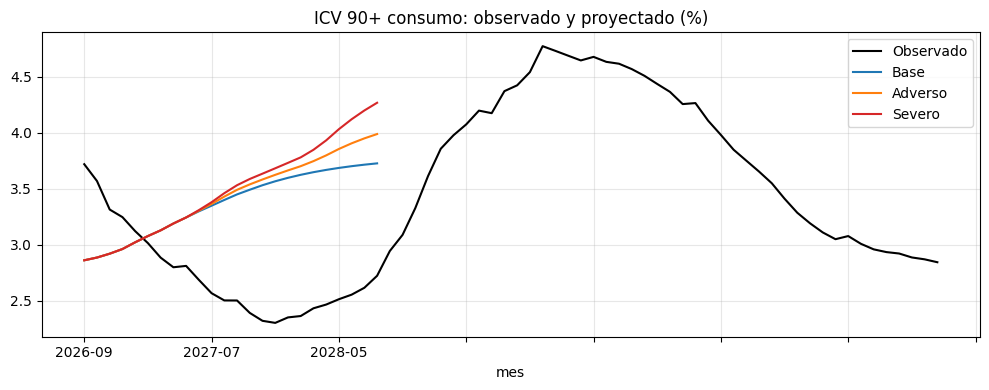

,pico,mes_pico,fin_horizonte
Base,0.0373,2028-08,0.0373
Adverso,0.0399,2028-08,0.0399
Severo,0.0427,2028-08,0.0427


In [11]:
esc = E.trayectorias_macro(d)
proy = {k: E.proyectar(sat, d, v) for k, v in esc.items()}
P = pd.DataFrame(proy)
fig, ax = plt.subplots(figsize=(10, 4))
(100 * s.icv90.loc["2021-01":]).plot(ax=ax, color="k", label="Observado")
for k, col in zip(P, ["tab:blue", "tab:orange", "tab:red"]):
    (100 * P[k]).plot(ax=ax, color=col, label=k)
ax.set_title("ICV 90+ consumo: observado y proyectado (%)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "escenarios.png", dpi=130); plt.show()
resumen = pd.DataFrame({"pico": P.max(), "mes_pico": P.idxmax(), "fin_horizonte": P.iloc[-1]})
resumen

In [12]:
crec_ult = d.crec.dropna().iloc[-1]
print(f"Crecimiento anual del saldo de consumo en el último mes: {crec_ult:.1f}%")
print(f"Aun en el escenario base el ICV90 pasa de {s.icv90.iloc[-1]:.2%} a {P['Base'].max():.2%}: la aceleración del crédito "
      "de 2025-2026 madura en mora con 12 meses de rezago aunque la macro no empeore.")
fin = P.iloc[-1]
print(f"Al final del horizonte, el adverso agrega {(fin['Adverso']-fin['Base'])*1e4:.0f} pb y el severo {(fin['Severo']-fin['Base'])*1e4:.0f} pb sobre el base.")

Crecimiento anual del saldo de consumo en el último mes: 10.6%
Aun en el escenario base el ICV90 pasa de 2.84% a 3.73%: la aceleración del crédito de 2025-2026 madura en mora con 12 meses de rezago aunque la macro no empeore.
Al final del horizonte, el adverso agrega 26 pb y el severo 54 pb sobre el base.


**Lectura.** El hallazgo de más valor no es el escenario severo sino el base: la expansión reciente del crédito ya trae
incorporado un aumento de la mora. Los escenarios de estrés se separan del base tarde y poco, porque los choques de tasa e
inflación tardan entre 9 y 15 meses en transmitirse y sus coeficientes son pequeños; esa baja sensibilidad es justamente
uno de los puntos que revisa la validación independiente.

## 7. De la mora a la pérdida: impacto por producto

In [13]:
betas = E.sensibilidades_producto(p, s)
imp = E.impacto_perdida(proy, s, p, betas)
print(betas.round(3))
tab = imp.pivot(index="producto", columns="escenario", values="perdida_incremental")[["Base", "Adverso", "Severo"]] / 1e12
tab.loc["Total"] = tab.sum()
print("\nPérdida incremental aproximada (billones de pesos) = (ICV90 pico - actual) x saldo x LGD supuesta")
tab.round(3)

                         a      b     r2
producto                                
Libranza           -2.3040 0.5270 0.6570
Libre inversión     1.3510 1.3000 0.9530
Tarjeta de crédito -0.2160 0.9000 0.8210
Vehículo            0.1080 0.9840 0.6600
Rotativo           -0.8660 0.6950 0.4250

Pérdida incremental aproximada (billones de pesos) = (ICV90 pico - actual) x saldo x LGD supuesta


escenario,Base,Adverso,Severo
producto,,,
Libranza,0.0930,0.1180,0.1450
Libre inversión,0.6810,0.8920,1.1200
Rotativo,0.0220,0.0280,0.0350
Tarjeta de crédito,0.2450,0.3160,0.3920
Vehículo,0.1080,0.1400,0.1740
Total,1.1490,1.4950,1.8660


In [14]:
sev = imp.query("escenario == 'Severo'").set_index("producto")
print(f"Severo: {cop_billones(sev.perdida_incremental.sum())}, "
      f"{sev.perdida_incremental.sum()/sev.saldo.sum():.2%} del saldo de los cinco productos.")
print(f"Libre inversión concentra {sev.perdida_incremental['Libre inversión']/sev.perdida_incremental.sum():.0%} de la pérdida "
      f"con {sev.saldo['Libre inversión']/sev.saldo.sum():.0%} del saldo (beta {betas.b['Libre inversión']:.2f} frente al sistema).")

Severo: 1,87 billones, 0.83% del saldo de los cinco productos.
Libre inversión concentra 60% de la pérdida con 30% del saldo (beta 1.30 frente al sistema).


## 8. Marco de apetito y semáforo

In [15]:
apetito = E.marco_apetito(p, imp)
apetito

,actual,apetito_p75,tolerancia_p90,capacidad_severo,estado
producto,,,,,
Libranza,0.0180,0.0173,0.0185,0.0223,Ámbar
Libre inversión,0.0373,0.0436,0.0657,0.0657,Verde
Tarjeta de crédito,0.0263,0.0386,0.0473,0.0473,Verde
Vehículo,0.0386,0.0421,0.0534,0.0573,Verde
Rotativo,0.0277,0.0425,0.0485,0.0485,Verde


In [16]:
sem = E.semaforo_entidades(c)
print(sem.senal.value_counts().to_string())
print(f"Saldo bajo 'Vigilar' o 'Seguimiento reforzado': {sem.loc[sem.senal!='Normal','saldo'].sum()/sem.saldo.sum():.1%}")
sem[["codigo", "tipo_entidad", "icv90", "vs_sistema", "delta_temprana_6m_pb", "senal"]].head(15)

senal
Normal                   25
Vigilar                   3
Seguimiento reforzado     1
Saldo bajo 'Vigilar' o 'Seguimiento reforzado': 4.0%


,codigo,tipo_entidad,icv90,vs_sistema,delta_temprana_6m_pb,senal
0,E01,Banco,0.0324,1.1391,0.7685,Normal
1,E02,Banco,0.0374,1.3165,-2.2836,Normal
2,E03,Banco,0.0262,0.9210,11.8088,Normal
3,E04,Banco,0.0307,1.0787,-25.3656,Normal
4,E05,Banco,0.0186,0.6524,-1.6497,Normal
5,E06,Banco,0.0200,0.7021,-24.9719,Normal
6,E07,Banco,0.0239,0.8390,0.9393,Normal
7,E08,Banco,0.0282,0.9912,-0.6148,Normal
8,E09,Banco,0.0102,0.3576,8.8310,Normal
9,E10,Banco,0.0199,0.6986,1.8879,Normal


Las entidades se publican con código anónimo: es una señal estadística sobre datos agregados públicos, útil para
priorizar revisión, y no sustituye la información de supervisión ni la de la propia entidad.

## 9. Memo para el comité

In [17]:
amb = apetito.index[apetito.estado != "Verde"].tolist()
print(f'''1. El deterioro 2023-2024 fue de calidad de originación dentro de libre inversión y tarjeta ({(ss.loc[["Libre inversión","Tarjeta de crédito"],"total"].sum()/tot):.0%} del cambio), no de mezcla.
2. Alerta: la mora 31-60 días anticipa la 90+ de cada entidad un trimestre antes (beta {pa["beta"]:.2f}, t {pa["t"]:.1f}). Debe estar en el tablero mensual.
3. Escenario base: el ICV90 sube de {s.icv90.iloc[-1]:.2%} a {P["Base"].max():.2%} por maduración del crédito que crece al {crec_ult:.0f}% anual.
4. Severo: pérdida incremental de {cop_billones(sev.perdida_incremental.sum())}; el {sev.perdida_incremental["Libre inversión"]/sev.perdida_incremental.sum():.0%} en libre inversión.
5. Productos fuera de apetito hoy: {", ".join(amb) if amb else "ninguno"}.
Decisiones propuestas: endurecer cortes de originación de libre inversión antes de que madure la cosecha 2025-2026;
fijar límites por producto en los percentiles 75/90 de la tabla; revisar mensualmente las entidades o segmentos con alerta temprana.''')

1. El deterioro 2023-2024 fue de calidad de originación dentro de libre inversión y tarjeta (81% del cambio), no de mezcla.
2. Alerta: la mora 31-60 días anticipa la 90+ de cada entidad un trimestre antes (beta 0.34, t 6.9). Debe estar en el tablero mensual.
3. Escenario base: el ICV90 sube de 2.84% a 3.73% por maduración del crédito que crece al 11% anual.
4. Severo: pérdida incremental de 1,87 billones; el 60% en libre inversión.
5. Productos fuera de apetito hoy: Libranza.
Decisiones propuestas: endurecer cortes de originación de libre inversión antes de que madure la cosecha 2025-2026;
fijar límites por producto en los percentiles 75/90 de la tabla; revisar mensualmente las entidades o segmentos con alerta temprana.


**Límites.** Datos agregados por entidad, no créditos; el ICV se mueve con castigos y ventas de cartera; LGD supuestas;
canal de tasa débilmente identificado; 104 meses de muestra efectiva con un periodo de alivios atípico. La validación
independiente de este modelo está en [`../02-validacion-modelo-satelite`](../02-validacion-modelo-satelite).

In [18]:
import json
res = {"icv90_ultimo": float(s.icv90.iloc[-1]), "mes_ultimo": s.index[-1], "rezagos": rez,
       "coeficientes": sat.params.round(5).to_dict(), "pico_por_escenario": P.max().round(5).to_dict(),
       "perdida_incremental_billones": (tab["Severo"]).round(4).to_dict(),
       "alerta_temprana": {"beta": pa["beta"], "t": pa["t"], "n": pa["n"]},
       "estado_apetito": apetito.estado.to_dict()}
Path("resultados").mkdir(exist_ok=True)
Path("resultados/resumen.json").write_text(json.dumps(res, indent=2, ensure_ascii=False, default=float))
sem.drop(columns=[]).to_csv("resultados/semaforo_entidades_anonimo.csv", index=False)
P.to_csv("resultados/proyeccion_escenarios.csv")
print("Resultados guardados.")

Resultados guardados.
